<span id="#toc" style='font-size: 20pt; font-weight: bold'>TABLE OF CONTENTS</span>

<span style='font-size: 15pt; text-decoration: none; display: block;'>
  <a href="#slidebar" style="font-size: 15pt; text-decoration: none;">
    Slide Bar 
  </a>
</span>

<span id='import-lib' style='color:#008000; font-size:20pt; font-weight:bold'>Import Libraries</span>

In [103]:
import pyvista as pv
import numpy as np
from collections import deque
# import open3d as o3d
import math
import copy

<span id='load-data' style='color:#008000; font-size:20pt; font-weight:bold'>Load Data </span>

In [104]:
import time

time_start = time.time()

mesh = pv.read('../CG_dataset/brick_part03.obj')
# cube_subdivide
# O_subdivide
# cuboctahedron_subdivide

In [105]:
# pcd = o3d.io.read_point_cloud("D:\\Learn_and_Study\\USTH\\Bachelor\\3D_Project\\CG_dataset\\brick_part01_smoothen.pcd")
# pcd.estimate_normals(search_param=o3d.geometry.KDTreeSearchParamKNN(knn=30))

# # RECONSTRUCT SURFACE MESH BY POISSON AND CONVERT INTO PYVISTA
# mesh_o3d, _ = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(pcd, depth=8)
# mesh_o3d.compute_vertex_normals()

# vertices = np.asarray(mesh_o3d.vertices)
# triangles = np.asarray(mesh_o3d.triangles)
# faces = np.hstack([np.full((len(triangles), 1), 3), triangles]).flatten()  # Add face header

# mesh_pv = pv.PolyData(vertices, faces)

In [106]:
# mesh = brick_part01
# mesh

<span style='color:#008000; font-size:20pt; font-weight:bold'>Curvature</span>

In [107]:
curvature = mesh.curvature(curv_type='mean')
# min_curv = np.fabs(mesh.curvature(curv_type='minimum'))
# max_curv = np.fabs(mesh.curvature(curv_type='maximum'))
# curvature = np.maximum(min_curv, max_curv)
clim = [np.percentile(curvature, 3), np.percentile(curvature, 90)]

Total points: 42202
Min: -552.7091, Max: 216.5478, Mean: 0.8521


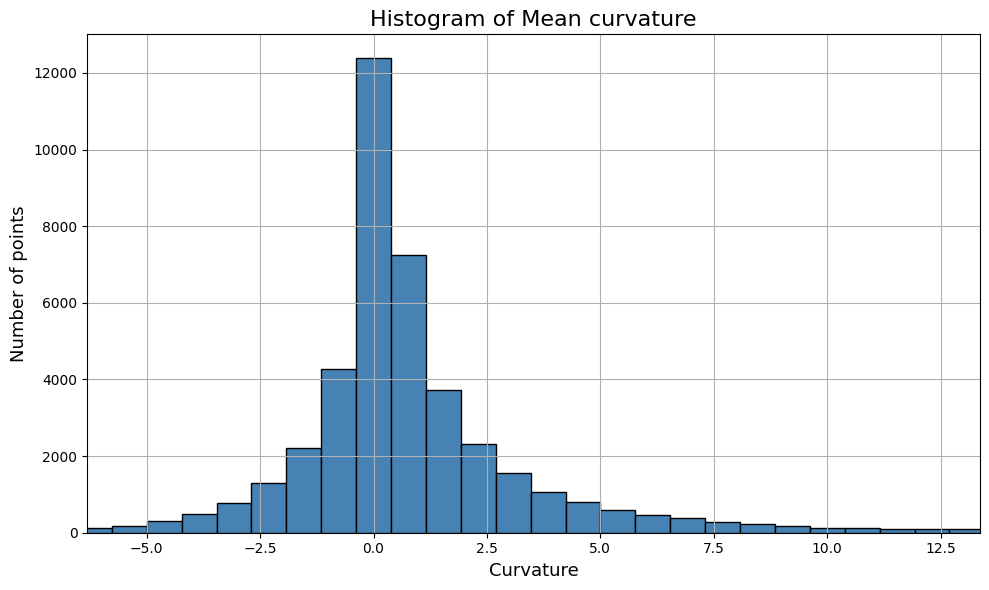

In [108]:
import matplotlib.pyplot as plt

print(f"Total points: {mesh.n_points}")
print(f"Min: {np.min(curvature):.4f}, Max: {np.max(curvature):.4f}, Mean: {np.mean(curvature):.4f}")

plt.figure(figsize=(10, 6))
plt.hist(curvature, bins=1000, color='steelblue', edgecolor='black')
plt.title(f"Histogram of Mean curvature", fontsize=16)
plt.xlabel("Curvature", fontsize=13), plt.ylabel("Number of points", fontsize=13)
plt.grid(True)
plt.tight_layout()
plt.xlim(np.percentile(curvature, 1), np.percentile(curvature, 99))
plt.show()

In [109]:
mesh['mean-curvature'] = curvature

<span style='color:#008000; font-size:20pt; font-weight:bold'>Neighbors Propagation</span>

<span style='color:#007ACC; font-size:15pt; font-weight:bold'>Mesh Simplification and Smoothing</span>

In [110]:
# import numpy as np
# import pyvista as pv
# from collections import defaultdict, deque

# def build_vertex_adjacency(faces: np.ndarray) -> dict[int, set[int]]:
#     """
#     Get adjacency of all vertices in the mesh.

#     Parameters:
#         faces (np.ndarray): An (N, 3) array where each row contains three vertex indices representing a triangle.

#     Returns:
#         dict[int, set[int]]: Dictionary mapping each vertex to a set of its adjacent vertices.
#     """
#     adjacency: dict[int, set[int]] = defaultdict(set)

#     for i, j, k in faces:
#         adjacency[i].update((j, k))
#         adjacency[j].update((i, k))
#         adjacency[k].update((i, j))

#     return adjacency

# def laplacian_smoothing(mesh: pv.PolyData, iterations=3):
    
#     # Extract face indices (reshape from PyVista's format)
#     faces = mesh.faces.reshape((-1, 4))[:, 1:]  # Drop the leading "3" of each triangle
#     adjacency = build_vertex_adjacency(faces)

#     points = mesh.points.copy()

#     for _ in range(iterations):
#         new_points = points.copy()
#         for i in range(len(points)):
#             neighbors = list(adjacency[i])
#             if not neighbors:
#                 continue
#             neighbor_coords = points[neighbors]
#             new_points[i] = neighbor_coords.mean(axis=0)
#         points = new_points  # update for next iteration

#     # Create a new smoothed mesh to avoid altering the original
#     smoothed_mesh = pv.PolyData(points, mesh.faces)
#     return smoothed_mesh

In [111]:
# import fast_simplification
# mesh = fast_simplification.simplify_mesh(brick_part01, target_reduction=0.5)
# mesh = mesh.smooth(n_iter=500)

# mesh = laplacian_smoothing(mesh)  

<span style='color:#007ACC; font-size:15pt; font-weight:bold'>Functions</span>

In [112]:
def significant_curvature_difference(curvature, point, n_rings, threshold):
    neighbors_flat = list()
    neighbors = mesh.point_neighbors_levels(point, n_rings)

    for i, neighbor in enumerate(neighbors):
        neighbors_flat.extend(neighbor)

    if len(neighbors_flat) == 0:
        raise Exception("The point has no neighbor")

    avg_curvature = np.mean(curvature[list(neighbors_flat)])

    # std_curvature = np.std(neighbor_curvatures)
    # if abs(std_curvature - avg_curvature) > threshold * std_curvature:

    return abs(curvature[point] - avg_curvature) >= threshold
    
def local_max_curvature_point(curvature, founded_points: list|set):
    if len(founded_points) == len(curvature): raise Exception("Has visited all points")
    curvature_copy = copy.deepcopy(curvature)
    for point in founded_points:
        curvature_copy[point] = -(math.inf)
    return np.argmax(curvature_copy)

def propagate_with_curvature_threshold(curvature, propagated, start_point, threshold):
    # threshold = np.percentile(mean_curvature, 90)
    if curvature[start_point] < threshold:
        raise Exception("Starting point does not satisfy curvature threshold")

    visited = set()
    queue = deque([start_point])  
    result = set()

    result.add(start_point)

    while queue:

        point = queue.popleft()
        if point in visited:
            continue
        visited.add(point)

        for neighbor in mesh.point_neighbors(point):
            if neighbor not in visited and neighbor not in propagated:
                if curvature[neighbor] >= threshold:
                    result.add(neighbor)
                    queue.append(neighbor)
    if result: 
        propagated.update(result)
        return result
    else: raise Exception("Propagation result is empty")

def local_max_curvature_point_on_edge(curvature, visited, n_ring_diff, diff_threshold, max_points_on_edge:list):
    while True:
        max_point = local_max_curvature_point(curvature, visited)
        if not significant_curvature_difference(curvature, max_point, n_rings=n_ring_diff, threshold=diff_threshold):
            max_points_on_edge.append(max_point)
            visited.add(max_point)
            break
        visited.add(max_point)

    print(f"Number of visited: {len(visited)}")
    print(f"Number of max_points_on_edge: {len(max_points_on_edge)}")

def scene_setting(plotter, edges: list|set=None, title: str=None, position: tuple=None):

    def list_has_sublist_or_subset(lst):
        return any(isinstance(e, list|set) for e in lst)
    
    if position: plotter.subplot(*position)
    if title: plotter.add_text(title)
    if edges:
        if list_has_sublist_or_subset(edges):
            for i, edge in enumerate(edges):
                plotter.add_mesh(mesh.points[(list(edge))], color=colors[i], point_size=10, render_points_as_spheres=True)    
        else: 
            plotter.add_mesh(mesh.points[(list(edges))], color=colors[0], point_size=10, render_points_as_spheres=True)    
             
    plotter.add_mesh(mesh.points[max_points_on_edge], color='white', point_size=12, render_points_as_spheres=True)
    plotter.add_mesh(mesh, show_edges=True, scalars=curvature, clim=clim)

# def screenshot():
    # import os
    # plotter = pv.Plotter(off_screen=True)
    # scene_setting(plotter)

    # for name, view in camera_views.items():
    #     plotter.camera_position = view
    #     plotter.screenshot(os.path.join(save_dir, f"result_{name}.png"))
    # plotter.close()

def erose_condition(edge, point, condition: str, n_rings=1):
    neighbors = mesh.point_neighbors_levels(point, n_levels=n_rings)
    neighbors = set().union(*neighbors)

    def most(iterable):
        lst = list(iterable)
        return sum(bool(x) for x in lst) > len(lst) // 2

    if condition == "most":
        return most(neighbor in edge for neighbor in neighbors)

    if condition == "all":
        return all(neighbor in edge for neighbor in neighbors)

def erosion(edge, condition: str = "most", n_rings=1, iterations=1, single_line: bool=False):
    '''
    Input: List of points as edge
    Output: List of points after removal
    Algorithm: If all or most n_ring_neighbors of a point belong to edge -> Keep the point
               Otherwise, remove the point
    '''
    edge_copy = set(copy.deepcopy(edge))

    while iterations != 0:
        removal_points = set()

        for point in edge_copy:
            if not erose_condition(edge_copy, point, condition=condition, n_rings=n_rings):
                removal_points.add(point)
        
        edge_copy.difference_update(removal_points)
        iterations -= 1
    return edge_copy

<span style='color:#008000; font-size:20pt; font-weight:bold'>Rendering</span>

In [113]:
all_point_ids = list(range(mesh.n_points))
visited = set()
max_points_on_edge = list()
edge_vertices = list()

iterations = 1
# thresholds = [0, 0, 0, 0]
thresholds = [1.5]

colors = ['red', 'dodgerblue', 'green', 'yellow', 'magenta', 'orangered', 'chocolate']

# camera_views = {
#         "xy_top": "xy",
#         "xz_front": "xz",
#         "yz_side": "yz",
#         "iso_view": "iso",
#         "corner_1": [-1, -1, 1],
#         "corner_2": [1, 1, 1],
#         "corner_3": [-1, 1, 1],
#         "corner_4": [1, -1, 1],
#         "bottom_up": [0, 0, -1],
#     }

# save_dir = "screenshots"

for i in range(iterations):
    local_max_curvature_point_on_edge(curvature, visited, 3, 1.0, max_points_on_edge)
    edge = propagate_with_curvature_threshold(curvature, visited, max_points_on_edge[i], thresholds[i])
    if edge:
        edge_vertices.append(edge)
        print(f"** Iteration {i}: {len(edge)} points | Max Curvature: {curvature[max_points_on_edge[i]]:.4f} | Average Curvature: {np.mean(curvature[list(edge)]):.4f}")
    else:
        print(f"** Iteration {i}: No points propagated — threshold = {thresholds[i]:.2f}")

erosed_edges_all = list()
erosed_edges_most = list()


for edge in edge_vertices:
    erosed = erosion(edge, condition="all")
    erosed_edges_all.append(erosed)

for edge in edge_vertices:
    erosed = erosion(edge, condition="most")
    erosed_edges_most.append(erosed)

# plotter = pv.Plotter(shape=(2, 2))

# scene_setting(plotter, title="Mesh", position=(0, 0))
# scene_setting(plotter, erosed_edges_all, title="Edges", position=(0, 1))
# scene_setting(plotter, erosed_edges_all, title="Erode: 'all' 1 time", position=(1, 0))
# scene_setting(plotter, erosed_edges_most, title="Erode: 'most' 1 time", position=(1, 1))

# plotter.show(cpos='xy')



Number of visited: 198
Number of max_points_on_edge: 1
** Iteration 0: 6637 points | Max Curvature: 17.5166 | Average Curvature: 4.9822


In [114]:
# import nbformat

# # 📌 BƯỚC 1: Đặt tên file notebook và file xuất ra
# notebook_file = "edge_detection_using_propagation.ipynb"     # 👉 đổi thành tên notebook của bạn
# output_file = "extract_code_from_ipynb.py"      # 👉 tên file .py để lưu code

# # 📌 BƯỚC 2: Đọc file notebook
# with open(notebook_file, "r", encoding="utf-8") as f:
#     nb = nbformat.read(f, as_version=4)

# # 📌 BƯỚC 3: Giả sử ô hiện tại đang chạy là ô cuối cùng (có thể điều chỉnh nếu cần)
# current_cell_index = len(nb.cells) - 1

# # 📌 BƯỚC 4: Lấy code từ tất cả các cell code phía trên
# code_above = ""
# for i in range(current_cell_index):
#     cell = nb.cells[i]
#     if cell.cell_type == "code":
#         code_above += cell.source + "\n\n"

# # 📌 BƯỚC 5: Lưu vào file .py
# with open(output_file, "w", encoding="utf-8") as f:
#     f.write(code_above)

# print(f"✅ Đã lưu mã từ các cell phía trên vào file: {output_file}")


In [115]:
gt_path = "../some_groundtruth/Brick3_GT.obj"
gt_mesh = pv.read(gt_path)

In [116]:
p = pv.Plotter(shape=(1, 2))

# p.subplot(0, 0)
# p.add_mesh(mesh, show_edges=True, color="aliceblue")
# p.add_mesh(mesh, color='lightgray', opacity=0.6)
# p.add_text(f'No_iter: {iterations}\nThreshold: {thresholds}', font_size=15)
# p.add_mesh(mesh.points[max_points_on_edge], color='white', point_size=15, render_points_as_spheres=True)
# # p.add_text(f'Before eroded', font_size=15)
# for i, edge in enumerate(edge_vertices):
#     if edge:
#         p.add_mesh(mesh.points[(list(edge))], color=colors[i], point_size=5)  
 
p.subplot(0, 0)
# p.add_text(f'Before eroded', font_size=15)
# p.add_text(f'No_iter: {iterations}\nThreshold: {thresholds}', font_size=15)
p.add_mesh(mesh, color='lightgray', opacity=0.6)
p.add_mesh(mesh.points[max_points_on_edge], color='white', point_size=15, render_points_as_spheres=True)
for i, edge in enumerate(erosed_edges_most):
    if edge:
        p.add_mesh(mesh.points[(list(edge))], color=colors[i], point_size=5) 

p.subplot(0, 1)
# p.add_text("Ground Truth", font_size=12)
p.add_mesh(gt_mesh) 


p.link_views()
# p.show(window_size=(1000, 700))
p.show(window_size=(3000, 1000))

Widget(value='<iframe src="http://localhost:55261/index.html?ui=P_0x19341693d90_6&reconnect=auto" class="pyvis…

## Hausdorff Distance

In [117]:
from scipy.spatial.distance import cdist

def load_ground_truth_points(gt_obj_path: str) -> np.ndarray:
    """
    Load ground truth edge points từ file .obj được export từ Blender.
    """
    gt_mesh = pv.read(gt_obj_path)
    return gt_mesh.points

def hausdorff_distance(pred_points: np.ndarray, gt_points: np.ndarray) -> float:
    """
    Tính Hausdorff Distance giữa 2 tập điểm 3D.
    """
    dists_pred_gt = cdist(pred_points, gt_points)
    dists_gt_pred = cdist(gt_points, pred_points)
    hd_pred_gt = np.max(np.min(dists_pred_gt, axis=1))
    hd_gt_pred = np.max(np.min(dists_gt_pred, axis=1))
    return max(hd_pred_gt, hd_gt_pred)

In [118]:
def get_predicted_edge_points(mesh: pv.PolyData, erosed_edges: list[set]) -> np.ndarray:
    """
    Trả về tất cả điểm (3D coordinates) từ danh sách các cạnh được phát hiện.
    """
    point_ids = set()
    for edge in erosed_edges:
        point_ids.update(edge)  # hợp nhất tất cả các point_id

    return mesh.points[list(point_ids)]


In [119]:
# Đường dẫn tới file ground truth (xuất từ Blender)

# Lấy điểm ground truth
gt_points = load_ground_truth_points(gt_path)

# Lấy điểm predicted edges từ code của bạn
pred_points = get_predicted_edge_points(mesh, erosed_edges_most)

# Tính Hausdorff Distance
hd = hausdorff_distance(pred_points, gt_points)
print(f"✅ Hausdorff Distance = {hd:.6f}")


✅ Hausdorff Distance = 1.045517
